Heart Disease Prediction Using Machine Learning	Train an XGBoost model by manually implementing gradient boosting with weak learners, compare its accuracy with Random Forest, and analyze feature importance differences between both models.

In [1]:
import pandas as pd
import random
import math
import matplotlib.pyplot as plt

# Load datasets
train_df = pd.read_csv("heart_disease_train.csv")
test_df = pd.read_csv("heart_disease_test.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

train_df = train_df[features + [target]].dropna().reset_index(drop=True)
test_df = test_df[features + [target]].dropna().reset_index(drop=True)

# Convert data to lists
X_train = train_df[features].values.tolist()
y_train = train_df[target].tolist()

X_test = test_df[features].values.tolist()
y_test = test_df[target].tolist()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 79
Testing rows: 21


In [2]:
# Decision stump: one feature and one threshold
def make_stump(X, residuals, feature_names):

    best_error = float("inf")
    best_stump = None

    for j in range(len(feature_names)):

        values = sorted(set(row[j] for row in X))

        for k in range(len(values) - 1):

            threshold = (values[k] + values[k + 1]) / 2

            left_values = []
            right_values = []

            for i in range(len(X)):

                if X[i][j] <= threshold:
                    left_values.append(residuals[i])
                else:
                    right_values.append(residuals[i])

            if not left_values or not right_values:
                continue

            left_value = sum(left_values) / len(left_values)
            right_value = sum(right_values) / len(right_values)

            error = 0

            for i in range(len(X)):

                if X[i][j] <= threshold:
                    prediction = left_value
                else:
                    prediction = right_value

                error += (residuals[i] - prediction) ** 2

            if error < best_error:

                best_error = error

                best_stump = {
                    "feature": j,
                    "threshold": threshold,
                    "left": left_value,
                    "right": right_value
                }

    return best_stump


# Train gradient boosting with residuals
learning_rate = 0.1
number_of_stumps = 10

base_prediction = sum(y_train) / len(y_train)

train_predictions = [base_prediction] * len(y_train)
test_predictions = [base_prediction] * len(y_test)

stumps = []
importance = {feature: 0 for feature in features}

for step in range(number_of_stumps):

    residuals = [
        y_train[i] - train_predictions[i]
        for i in range(len(y_train))
    ]

    stump = make_stump(X_train, residuals, features)

    if stump is None:
        break

    stumps.append(stump)
    importance[features[stump["feature"]]] += 1

    # Update training predictions
    for i in range(len(X_train)):

        if X_train[i][stump["feature"]] <= stump["threshold"]:
            value = stump["left"]
        else:
            value = stump["right"]

        train_predictions[i] += learning_rate * value

    # Update testing predictions
    for i in range(len(X_test)):

        if X_test[i][stump["feature"]] <= stump["threshold"]:
            value = stump["left"]
        else:
            value = stump["right"]

        test_predictions[i] += learning_rate * value

# Convert predictions to classes
boost_predictions = [
    1 if value >= 0.5 else 0
    for value in test_predictions
]

print("Gradient boosting training completed.")
print("Number of decision stumps:", len(stumps))

Gradient boosting training completed.
Number of decision stumps: 10


In [4]:
# Calculate Gini impurity
def gini(labels):
    counts = {}

    for label in labels:
        counts[label] = counts.get(label, 0) + 1

    result = 1

    for count in counts.values():
        result -= (count / len(labels)) ** 2

    return result


# Find the majority class
def majority(labels):
    counts = {}

    for label in labels:
        counts[label] = counts.get(label, 0) + 1

    return max(counts, key=counts.get)


# Find the best split
def best_split(data, selected_features):

    best_gain = 0
    best_feature = None
    best_threshold = None

    parent_labels = data[target].tolist()
    parent_gini = gini(parent_labels)

    for feature in selected_features:

        values = sorted(set(data[feature].tolist()))

        for i in range(len(values) - 1):

            threshold = (values[i] + values[i + 1]) / 2

            left = data[data[feature] <= threshold]
            right = data[data[feature] > threshold]

            if len(left) == 0 or len(right) == 0:
                continue

            weighted_gini = (
                len(left) / len(data) * gini(left[target].tolist())
                + len(right) / len(data) * gini(right[target].tolist())
            )

            gain = parent_gini - weighted_gini

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold


# Build one tree
def build_tree(data, depth=0, max_depth=4):

    labels = data[target].tolist()

    if len(set(labels)) == 1 or depth == max_depth or len(data) < 5:
        return {"leaf": True, "prediction": majority(labels)}

    selected = random.sample(
        features,
        max(1, int(math.sqrt(len(features))))
    )

    feature, threshold = best_split(data, selected)

    if feature is None:
        return {"leaf": True, "prediction": majority(labels)}

    left = data[data[feature] <= threshold]
    right = data[data[feature] > threshold]

    if len(left) == 0 or len(right) == 0:
        return {"leaf": True, "prediction": majority(labels)}

    return {
        "leaf": False,
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(left, depth + 1, max_depth),
        "right": build_tree(right, depth + 1, max_depth)
    }


# Train 10 trees using bootstrap samples
forest = []

for i in range(10):

    sample_indices = [
        random.randint(0, len(train_df) - 1)
        for _ in range(len(train_df))
    ]

    sample = train_df.iloc[sample_indices].reset_index(drop=True)

    forest.append(build_tree(sample))

print("Random Forest trained successfully!")
print("Number of trees:", len(forest))

Random Forest trained successfully!
Number of trees: 10


In [6]:
# Predict using one decision tree
def predict_tree(tree, row):

    if tree["leaf"]:
        return tree["prediction"]

    feature = tree["feature"]

    if row[feature] <= tree["threshold"]:
        return predict_tree(tree["left"], row)

    return predict_tree(tree["right"], row)


# Predict using Random Forest majority voting
def predict_forest(forest, row):

    votes = {}

    for tree in forest:

        prediction = predict_tree(tree, row)

        votes[prediction] = votes.get(prediction, 0) + 1

    return max(votes, key=votes.get)


print("Random Forest prediction functions are ready!")

Random Forest prediction functions are ready!


Random Forest Accuracy: 85.71 %
Gradient Boosting Accuracy: 76.19 %

Feature Importance Comparison
 Feature  Random Forest Importance  Gradient Boosting Importance
     age                     0.276                           0.7
trestbps                     0.184                           0.0
    chol                     0.289                           0.3
 thalach                     0.066                           0.0
 oldpeak                     0.184                           0.0


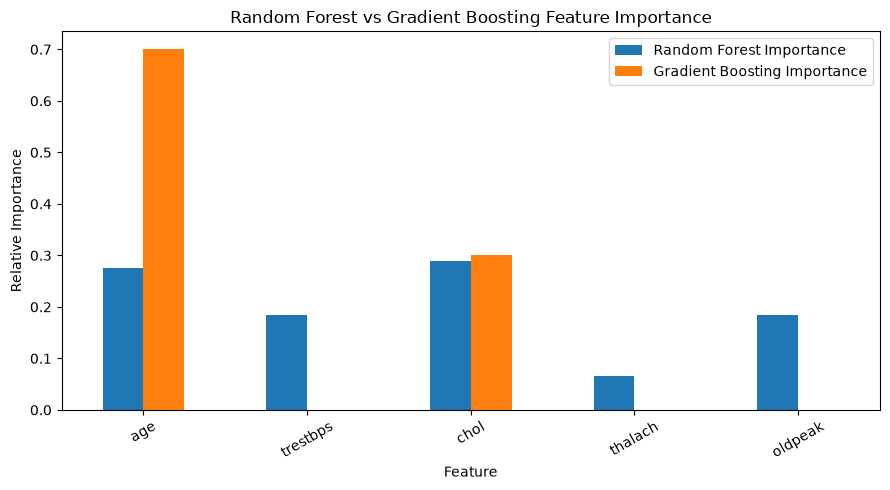

In [7]:
# Calculate gradient boosting accuracy manually
boost_correct = 0

for i in range(len(y_test)):

    if int(y_test[i]) == boost_predictions[i]:
        boost_correct += 1

boost_accuracy = boost_correct / len(y_test) * 100


# Use your Random Forest from the previous task
# This assumes forest and predict_forest are still available.
rf_predictions = [
    predict_forest(forest, test_df.iloc[i])
    for i in range(len(test_df))
]

rf_correct = 0

for i in range(len(y_test)):

    if int(y_test[i]) == int(rf_predictions[i]):
        rf_correct += 1

rf_accuracy = rf_correct / len(y_test) * 100


print("Random Forest Accuracy:", round(rf_accuracy, 2), "%")
print("Gradient Boosting Accuracy:", round(boost_accuracy, 2), "%")


# Compare feature importance
# Random Forest importance: count the features used in its trees
rf_importance = {feature: 0 for feature in features}

def count_tree_features(tree):

    if tree["leaf"]:
        return

    rf_importance[tree["feature"]] += 1

    count_tree_features(tree["left"])
    count_tree_features(tree["right"])

for tree in forest:
    count_tree_features(tree)

# Normalize both importance scores
rf_total = sum(rf_importance.values())
boost_total = sum(importance.values())

for feature in features:

    rf_importance[feature] = (
        rf_importance[feature] / rf_total
        if rf_total else 0
    )

    importance[feature] = (
        importance[feature] / boost_total
        if boost_total else 0
    )

comparison = pd.DataFrame({
    "Feature": features,
    "Random Forest Importance": [
        rf_importance[f] for f in features
    ],
    "Gradient Boosting Importance": [
        importance[f] for f in features
    ]
})

print("\nFeature Importance Comparison")
print(comparison.round(3).to_string(index=False))

# Plot comparison
comparison.set_index("Feature").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Random Forest vs Gradient Boosting Feature Importance")
plt.ylabel("Relative Importance")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()